In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import imblearn
import sklearn
import pickle
import shap

import sklearn.decomposition as skdecomp
import sklearn.ensemble as skens
import sklearn.svm as sksvm
import sklearn.linear_model as sklin

from sklearn.model_selection import GridSearchCV,StratifiedGroupKFold,StratifiedKFold,KFold
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from pychemauth.classifier.simca import SIMCA_Authenticator
from pychemauth.manifold.elliptic import EllipticManifold_Authenticator
from pychemauth.classifier.plsda import PLSDA
#from pychemauth.analysis.compare import Compare
from pychemauth.preprocessing.scaling import CorrectedScaler

from pychemauth.classifier.osr import OpenSetClassifier

from pychemauth_compare_ext import Compare_reg

2026-08-17 15:58:45.977042: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import multiphase_flow_utils
from multiphase_flow_utils import generate_models,extract_best_estimator
from multiphase_flow_utils import read_and_split_file,strip_constant,prune_threshold
from multiphase_flow_utils import fit_models,generate_kfolds,cross_validate
from multiphase_flow_utils import generate_kfolds,cross_validate,compute_scores
from multiphase_flow_utils import compute_fit,compute_vals,plot_fit,plot_vals

In [3]:
file = 'combined_process.xlsx'

In [4]:
study_pickle_file = file.split('.')[0] + '_study.pkl'
ydata_col = 'Erro ([%])'

Erro ([%])
True
True
                           Absolute pressure ([kPa])  Temp. ([°C])  \
Absolute pressure ([kPa])                   1.000000      0.139149   
Temp. ([°C])                                0.139149      1.000000   
ρ ([kg/m³])                                 0.970828      0.082797   
Visc. ([Pa.s])                             -0.166270      0.427100   
Reynolds x 10-3                             0.442768      0.650755   
SOS ([m/s])                                -0.461250      0.173257   
M ([#])                                    -0.039568      0.728514   
α·λ ([#])                                  -0.697347     -0.217222   
N2 ([%])                                   -0.475431      0.036093   
O2 ([%])                                   -0.080335      0.036707   
Ar ([%])                                   -0.081097      0.036735   
CO2 ([%])                                   0.521268     -0.053036   
Q Vol / Vel (m²)                           -0.137061     -0.071498   

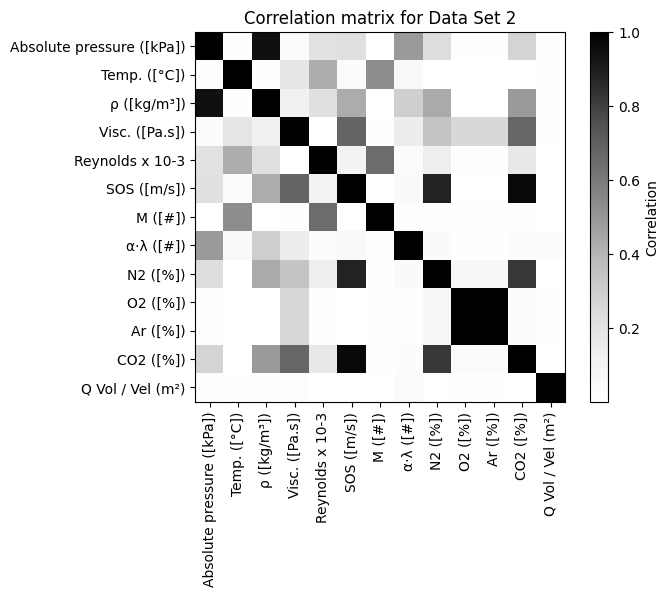

In [5]:
all_x,all_y = read_and_split_file(
    file,ydata_col
)

print(all_x.corr())

fig,ax=plt.subplots()
h = ax.imshow(
    np.square(all_x.corr().values),
    cmap='Grays'
)
cb = plt.colorbar(h,ax=ax)
cb.set_label(r'Correlation')
ax.set_title('Correlation matrix for Data Set 2')
ax.set_xticks(
    np.arange(len(all_x.T)),
    labels=all_x.columns.values,
    rotation='vertical'
)
#l = ax.set_xticklabels(,)
t = ax.set_yticks(
    np.arange(len(all_x.T)),
    labels=all_x.columns.values,
)
#l = ax.set_yticklabels(this_study.data[0].columns.values)

In [6]:
this_study = multiphase_flow_utils.flow_study(
    file=file,
    ydata_col=ydata_col,
    drop_xdata_cols=[
        'Pressão absoluta ([kPa])',
        #'Reynolds x 10-3',
        #'Vel (m/s)',
        #'Q Vol ref ([m³/h])',
        'M ([#])',
        'ρ ([kg/m³])',
        'O2 ([%])',
        'CO2 ([%])'
    ],
    train_size=0.8,
    split_random_state=42,
    kfold_repeats=40,
    products=True,triples=False,
)

this_study.fit_and_cv()

with open(study_pickle_file,'wb') as f:
    print(study_pickle_file)
    pickle.dump(this_study,f,protocol=4)

Erro ([%])
Index(['Pressão absoluta ([kPa])', 'Temp. ([°C])', 'ρ ([kg/m³])',
       'Visc. ([Pa.s])', 'Vel (m/s)', 'Reynolds x 10-3', 'Q Vol ref ([m³/h])',
       'SOS ([m/s])', 'M ([#])', 'α·λ ([#])', 'N2 ([%])', 'O2 ([%])',
       'Ar ([%])', 'CO2 ([%])'],
      dtype='str')
True
True
Beginning model training
OLS
Fitting 5 folds for each of 4 candidates, totalling 20 fits
PLS
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Linear SVR
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Pareto Poly SVR
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Scaled Poly SVR
Fitting 5 folds for each of 18 candidates, totalling 90 fits
RBF SVR
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Pareto RBF SVR
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Scaled RBF SVR
Fitting 5 folds for each of 18 candidates, totalling 90 fits
LASSO
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Ridge
Fitting 5 folds for each of 9 candidates

array([[<Axes: xlabel='Temp. (°C)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='Visc. (Pa.s)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='Reynolds x 10-3', ylabel='Temp. (°C)'>,
        <Axes: xlabel='SOS (m/s)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='α·λ (#)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='N2 (%)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='Ar (%)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='Q Vol / Vel (m²)', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(Temp. (°C))²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(Visc. (Pa.s))²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(Reynolds x 10-3)²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(SOS (m/s))²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(α·λ (#))²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(N2 (%))²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(Ar (%))²', ylabel='Temp. (°C)'>,
        <Axes: xlabel='(Q Vol / Vel (m²))²', ylabel='Temp. (°C)'>],
       [<Axes: xlabel='Temp. (°C)', ylabel='V

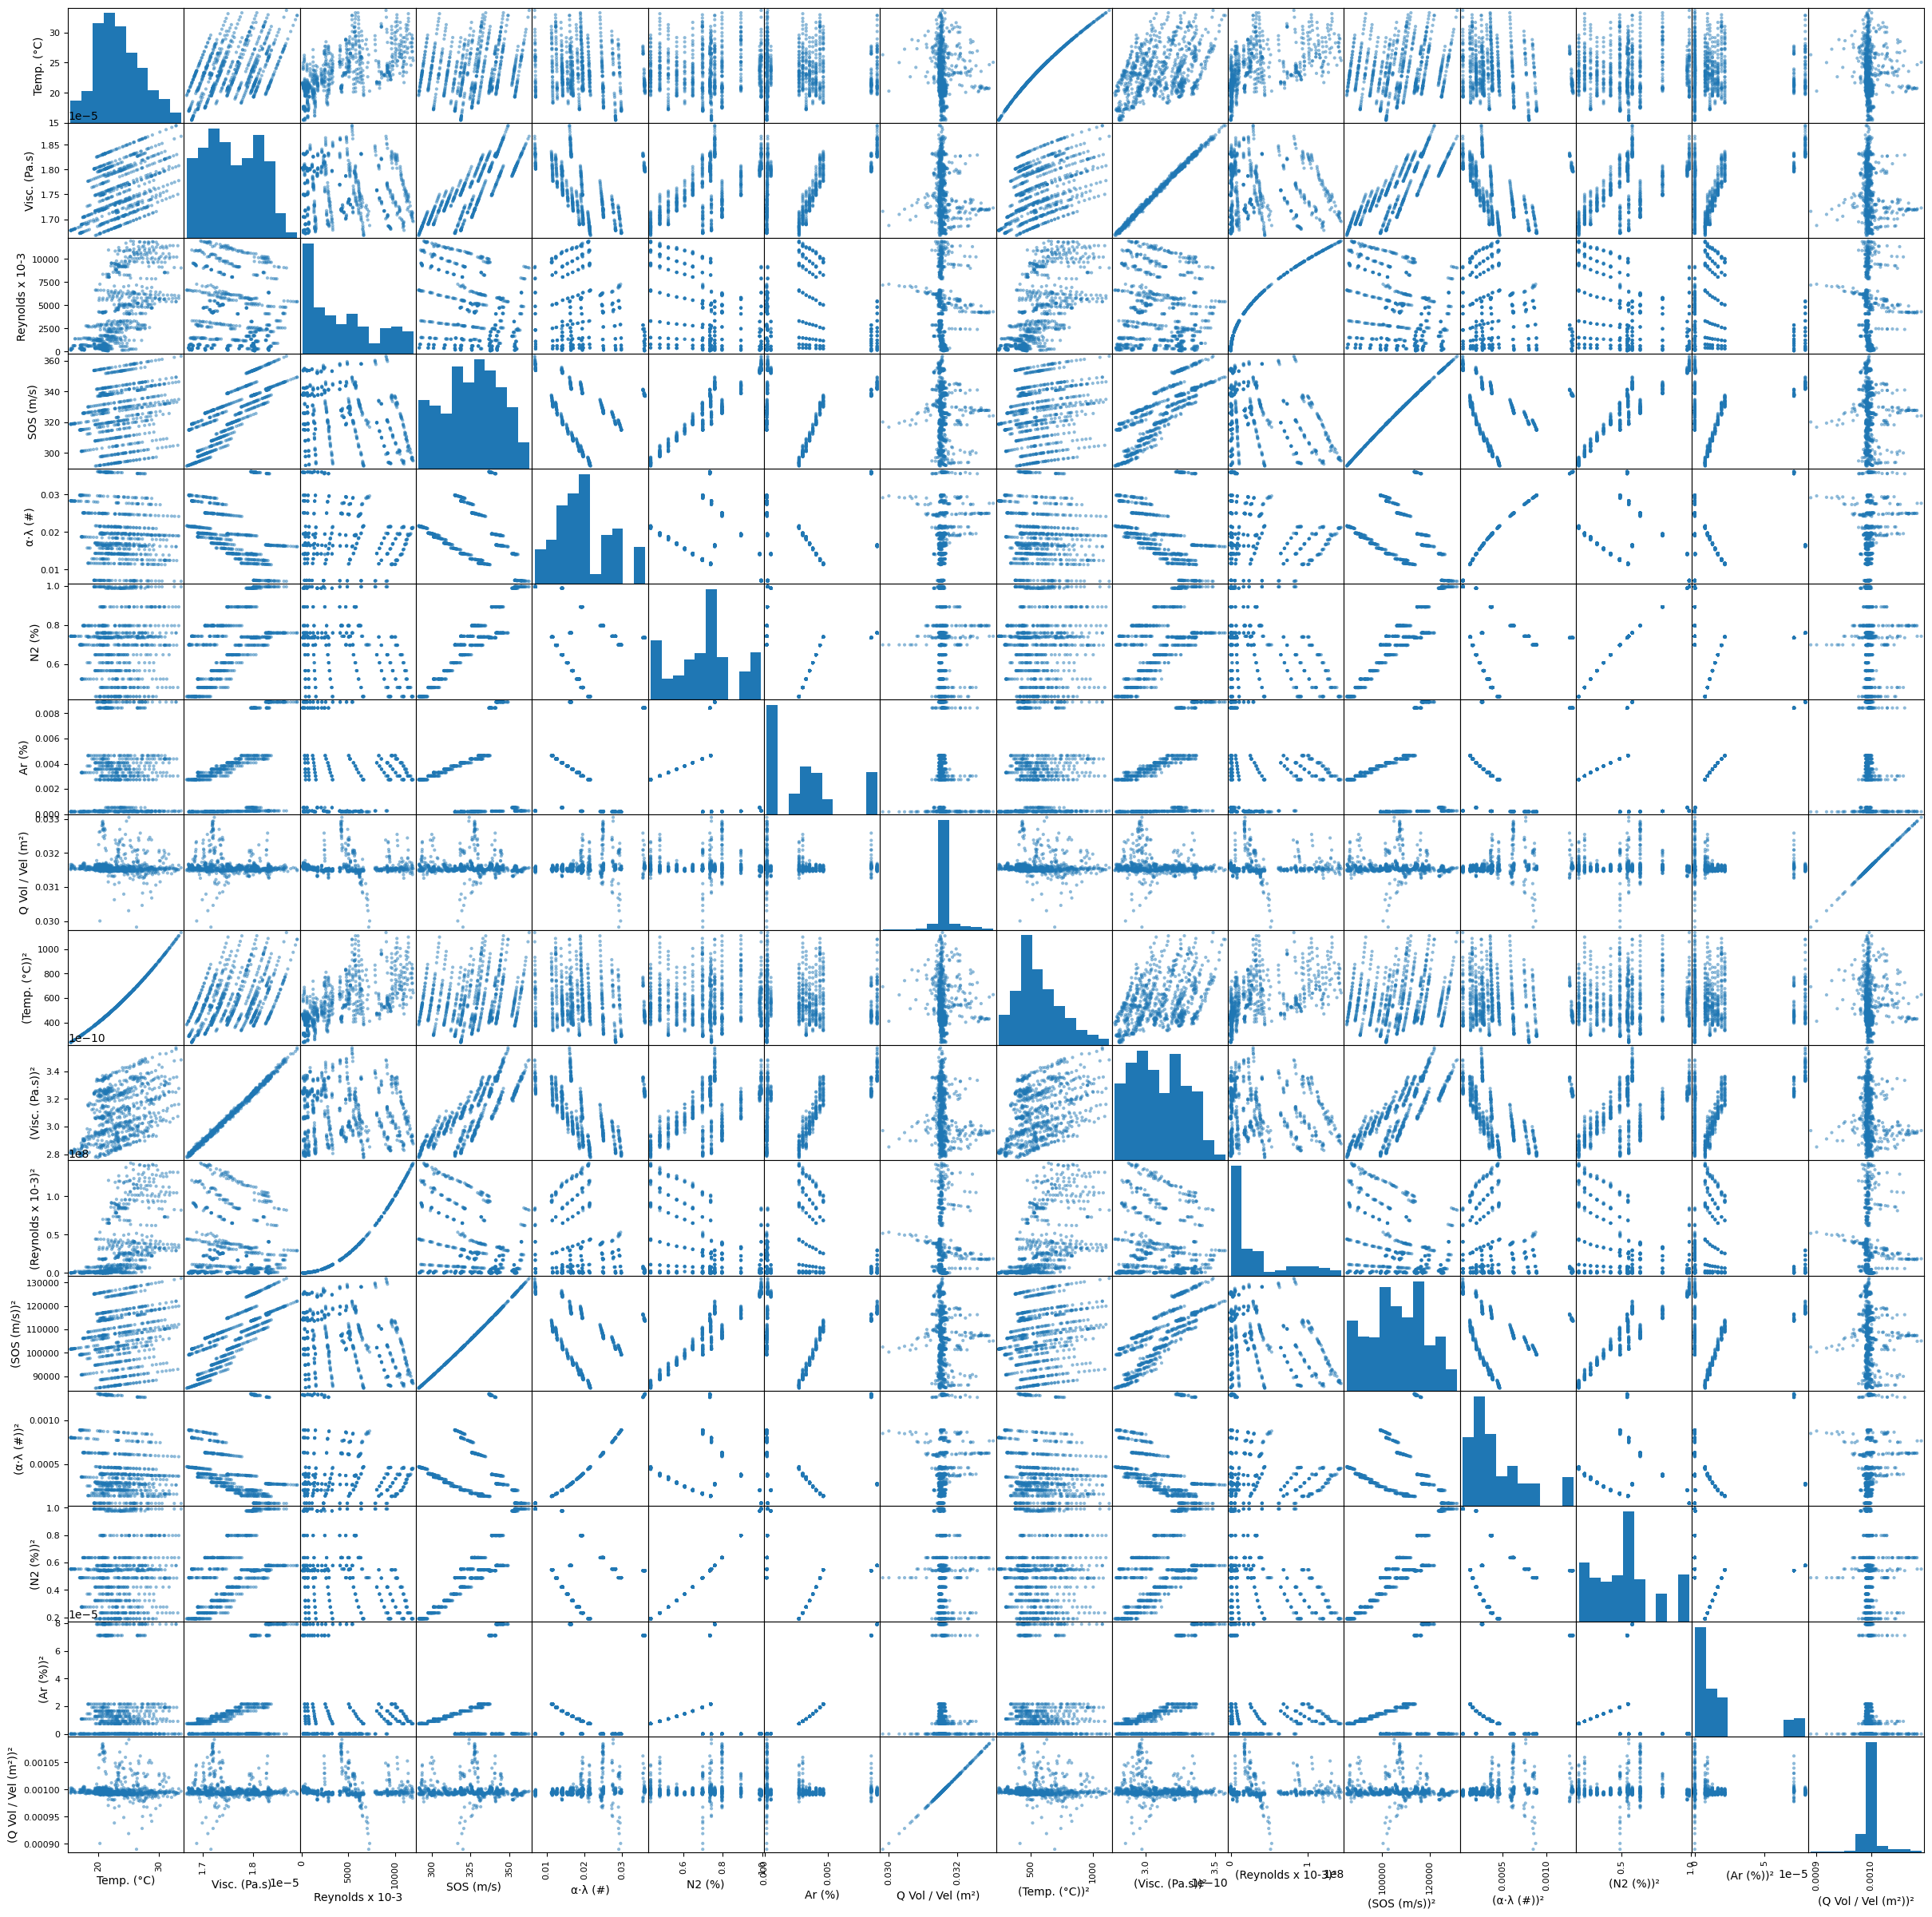

In [7]:
pd.plotting.scatter_matrix(
    this_study.data[0],
    figsize=(30,30)
)

In [8]:
this_study.data[0].corr()

,Temp. (°C),Visc. (Pa.s),Reynolds x 10-3,SOS (m/s),α·λ (#),N2 (%),Ar (%),Q Vol / Vel (m²),(Temp. (°C))²,(Visc. (Pa.s))²,(Reynolds x 10-3)²,(SOS (m/s))²,(α·λ (#))²,(N2 (%))²,(Ar (%))²,(Q Vol / Vel (m²))²
Temp. (°C),1.000000,0.427100,0.650755,0.173257,-0.217222,0.036093,0.036735,-0.071498,0.995236,0.427597,0.571594,0.176755,-0.219324,0.048929,0.007927,-0.070848
Visc. (Pa.s),0.427100,1.000000,-0.054254,0.819769,-0.379447,0.584897,0.502799,-0.124115,0.416027,0.998420,-0.084674,0.820697,-0.260583,0.563628,0.584935,-0.125877
Reynolds x 10-3,0.650755,-0.054254,1.000000,-0.312426,-0.182149,-0.368482,-0.075284,-0.023606,0.641029,-0.052742,0.962124,-0.309991,-0.222410,-0.346782,-0.208634,-0.022023
SOS (m/s),0.173257,0.819769,-0.312426,1.000000,-0.224075,0.939563,0.056893,-0.043935,0.173838,0.816745,-0.364258,0.999570,-0.103539,0.921340,0.264163,-0.044105
α·λ (#),-0.217222,-0.379447,-0.182149,-0.224075,1.000000,-0.188108,0.082285,0.170070,-0.206946,-0.376278,-0.186218,-0.234181,0.978494,-0.235739,0.204778,0.172542
N2 (%),0.036093,0.584897,-0.368482,0.939563,-0.188108,1.000000,-0.262964,0.000412,0.042926,0.580698,-0.426993,0.938894,-0.089047,0.991500,-0.035388,0.001092
Ar (%),0.036735,0.502799,-0.075284,0.056893,0.082285,-0.262964,1.000000,-0.083036,0.019852,0.505829,-0.025826,0.053348,0.128322,-0.309265,0.946748,-0.085673
Q Vol / Vel (m²),-0.071498,-0.124115,-0.023606,-0.043935,0.170070,0.000412,-0.083036,1.000000,-0.073805,-0.125676,-0.039383,-0.046548,0.145782,-0.007399,-0.048228,0.999896
(Temp. (°C))²,0.995236,0.416027,0.641029,0.173838,-0.206946,0.042926,0.019852,-0.073805,1.000000,0.416865,0.568003,0.176862,-0.209861,0.053281,-0.004746,-0.073274
(Visc. (Pa.s))²,0.427597,0.998420,-0.052742,0.816745,-0.376278,0.580698,0.505829,-0.125676,0.416865,1.000000,-0.082728,0.817892,-0.257735,0.559877,0.589247,-0.127417


In [9]:
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_study.cv_score(score_name=name,score_fun=metric)

mae
rmse
r2
mape
medae
maxe


In [10]:
this_study.train[1]

,Erro ([%])
477,-0.209127
346,-0.195436
462,-0.229910
670,-3.107814
302,-0.258507
...,...
71,0.446198
106,-0.544364
270,-0.013992
435,-0.227034


In [11]:
scores = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.train,score_name=name,score_fun=metric)
    #print(this_score)
    scores = dict(**scores,**this_score)
pd.DataFrame.from_dict(scores)

,mae,rmse,r2,mape,medae,maxe
OLS,0.000324,0.000669,0.999999,0.000977,0.000156,0.010227
PLS,0.000336,0.000681,0.999999,0.001015,0.000176,0.010396
Linear SVR,0.049716,0.056939,0.995437,0.165567,0.047768,0.354938
Pareto Poly SVR,0.409958,0.852365,-0.022584,1.026829,0.171240,5.748792
Scaled Poly SVR,0.049243,0.057556,0.995337,0.206423,0.048009,0.100480
RBF SVR,0.363808,0.798856,0.101776,0.807027,0.116325,5.193376
Pareto RBF SVR,0.085395,0.090007,0.988598,0.336589,0.099822,0.205866
Scaled RBF SVR,0.051150,0.058819,0.995131,0.199606,0.049342,0.100527
LASSO,0.009616,0.025931,0.999054,0.025086,0.004971,0.464907
Ridge,0.001779,0.004359,0.999973,0.004165,0.000944,0.079386


In [12]:
scores = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.test,score_name=name,score_fun=metric)
    #print(this_score)
    scores = dict(**scores,**this_score)
pd.DataFrame.from_dict(scores)

,mae,rmse,r2,mape,medae,maxe
OLS,0.000323,0.000655,1.000000,0.000853,0.000189,0.006319
PLS,0.000329,0.000665,1.000000,0.000899,0.000180,0.006468
Linear SVR,0.049527,0.058391,0.996682,0.154845,0.049070,0.262730
Pareto Poly SVR,0.481781,1.024551,-0.021551,0.800013,0.164227,5.119261
Scaled Poly SVR,0.044069,0.055589,0.996993,0.136310,0.037045,0.253680
RBF SVR,0.431653,0.954866,0.112685,0.607090,0.121604,4.585462
Pareto RBF SVR,0.459569,0.902202,0.207862,1.011259,0.223274,5.308206
Scaled RBF SVR,0.058258,0.108423,0.988560,0.161324,0.043286,1.129709
LASSO,0.010812,0.037876,0.998604,0.019005,0.004354,0.385276
Ridge,0.002166,0.006245,0.999962,0.003543,0.000940,0.063043


OLS
PLS
Ridge
ElasticNet
LASSO
Random Forest
Linear SVR
Scaled Poly SVR
Scaled RBF SVR
XGBoost
Pareto RBF SVR
RBF SVR
Pareto Poly SVR
OLS ,  PLS
OLS ,  Ridge
OLS ,  ElasticNet
OLS ,  LASSO
OLS ,  Random Forest
OLS ,  Linear SVR
OLS ,  Scaled Poly SVR
OLS ,  Scaled RBF SVR
OLS ,  XGBoost
OLS ,  Pareto RBF SVR
OLS ,  RBF SVR
OLS ,  Pareto Poly SVR
[['OLS', 0.9999994604406379, array([[2.08581376e-07],
       [8.82678338e-08]]), False], ['PLS', 0.9999994339551856, array([[1.87064882e-07],
       [9.56379109e-08]]), True], ['Ridge', 0.999980452081622, array([[7.21529770e-06],
       [3.74698172e-06]]), True], ['ElasticNet', 0.9994888512815718, array([[0.00049548],
       [0.00021642]]), True], ['LASSO', 0.9994884535504368, array([[0.00049661],
       [0.00021662]]), True], ['Random Forest', 0.9966713143261395, array([[0.00733592],
       [0.00211016]]), False], ['Linear SVR', 0.9951853119343239, array([[0.00136125],
       [0.0009179 ]]), True], ['Scaled Poly SVR', 0.9926084921597951, array

<PolarAxes: title={'center': 'Score +/- $\\sigma$'}>

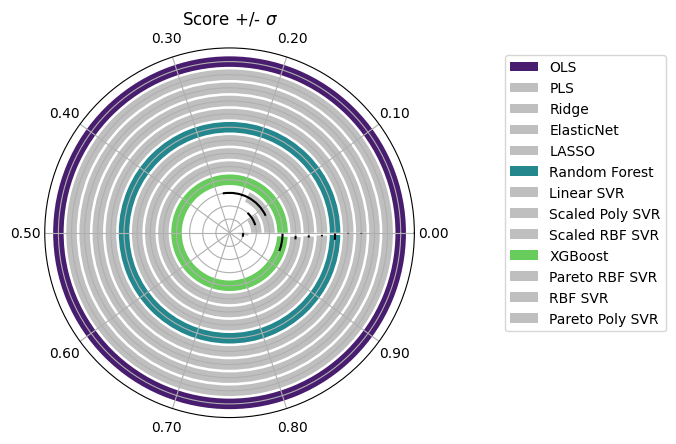

In [13]:
Compare_reg.visualize(
    this_study.cv_scores['r2'],
    n_repeats=this_study.kfold_repeats,asymmetric=True
)    

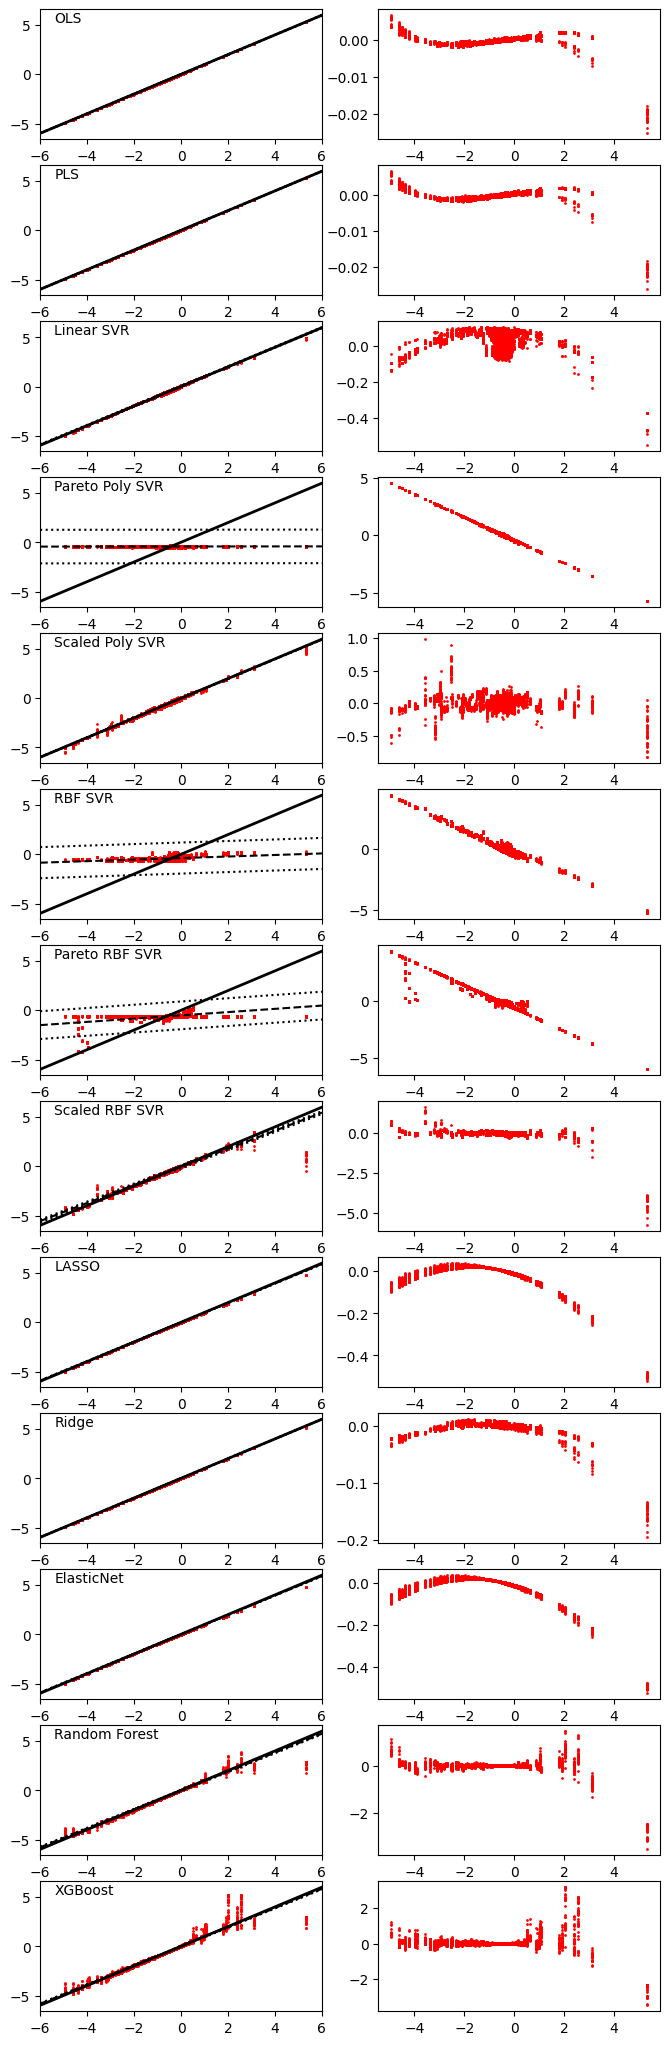

In [14]:
yt = np.squeeze(this_study.train[1].values)
cvs_dict = this_study.cvs_dict
n_repeats = this_study.kfold_repeats

nplots = len(cvs_dict)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))

for (name,cvs),ax_cal,ax_res in zip(cvs_dict.items(),axs[:,0],axs[:,1], ):
    
    coefs,covar,fit_err = compute_fit(yt,cvs,n_repeats)
    
    plot_vals(ax_cal,yt,cvs)
    plot_vals(ax_res,yt,cvs,resid=True)
    
    plot_fit(ax_cal,coefs,covar,fit_err)
    ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)

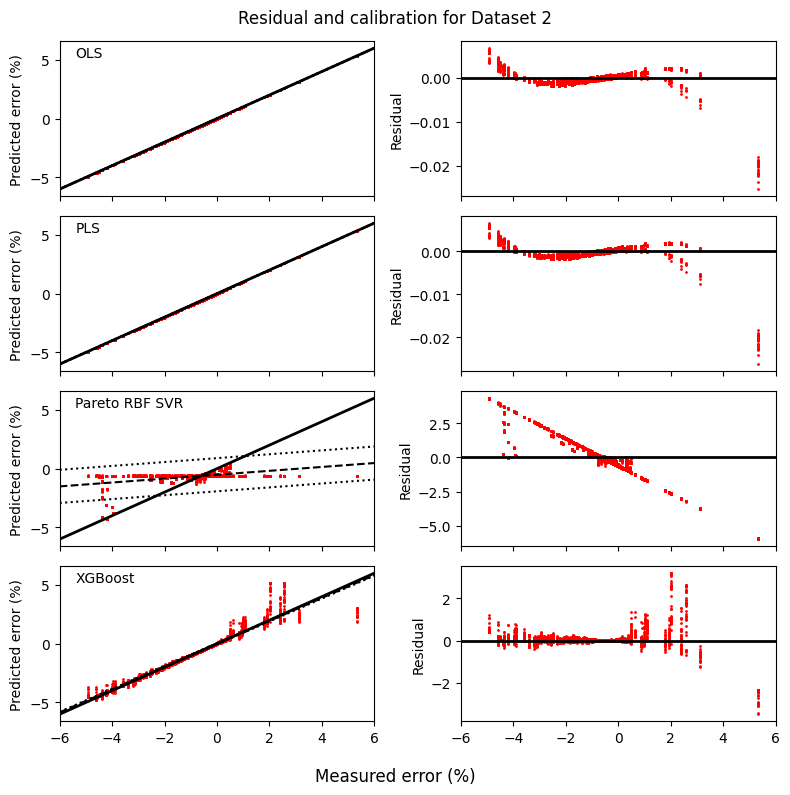

In [15]:
names_detailed = [
    'OLS',
    'PLS',
    'Pareto RBF SVR',
    'XGBoost',
]

cvs_detailed = {
    key:cvs_dict[key] for key in names_detailed
}

nplots = len(cvs_detailed)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots),sharex=True)

fig.suptitle(
    'Residual and calibration for Dataset 2', 
)
fig.supxlabel('Measured error (%)')
for (name,cvs),ax_cal,ax_res in zip(cvs_detailed.items(),axs[:,0],axs[:,1], ):
    
    coefs,covar,fit_err = compute_fit(yt,cvs,n_repeats)
    
    plot_vals(ax_cal,yt,cvs)
    plot_vals(ax_res,yt,cvs,resid=True)
    
    plot_fit(ax_cal,coefs,covar,fit_err)
    ax_res.axhline(y=0,ls='-',color='k',lw=2)
    ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)
    #ax_cal.text(0.95,0.1,'Calib',transform=ax_cal.transAxes,ha='right')
    #ax_res.text(0.95,0.1,'Resid',transform=ax_res.transAxes,ha='right')
    ax_cal.set_ylabel('Predicted error (%)')
    ax_res.set_ylabel('Residual')
#ax_cal.set_xlabel('Measured error (%)')
#ax_res.set_xlabel('Measured error (%)')
fig.tight_layout()

In [16]:
med = np.median(this_study.train[0],axis=0)[None,:,]
print(med.shape)

def f(x):
    #return this_study.best_models['Pareto RBF SVR'].predict(x)
    return this_study.best_models['PLS'].predict(x)

ex1 = shap.Explainer(f,med)
shap_train = ex1(this_study.train[0],max_evals=1000)
shap_values = ex1(this_study.test[0],max_evals=1000)

(1, 16)


PermutationExplainer explainer: 665it [00:10,  1.68s/it]                 


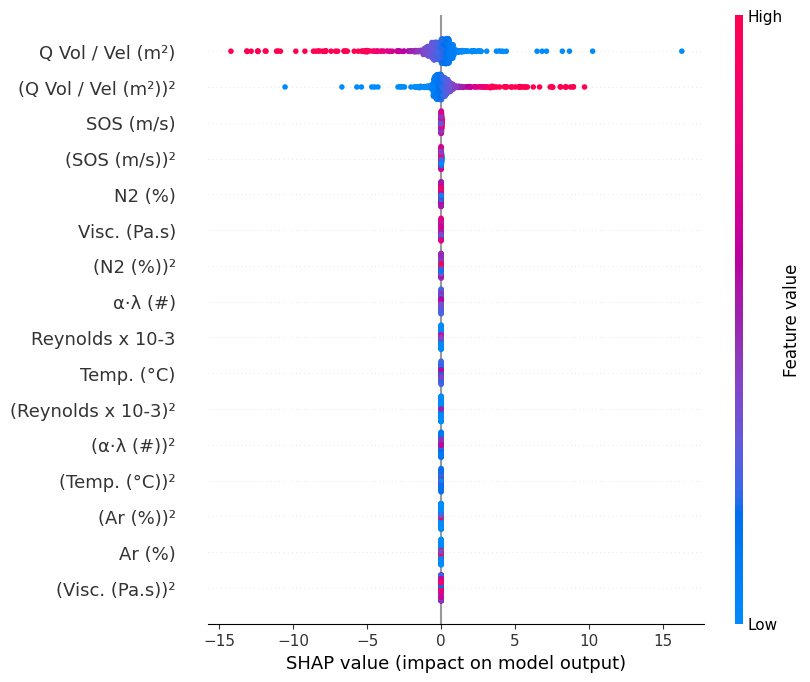

In [17]:
shap.plots.beeswarm(shap_train,max_display=50)

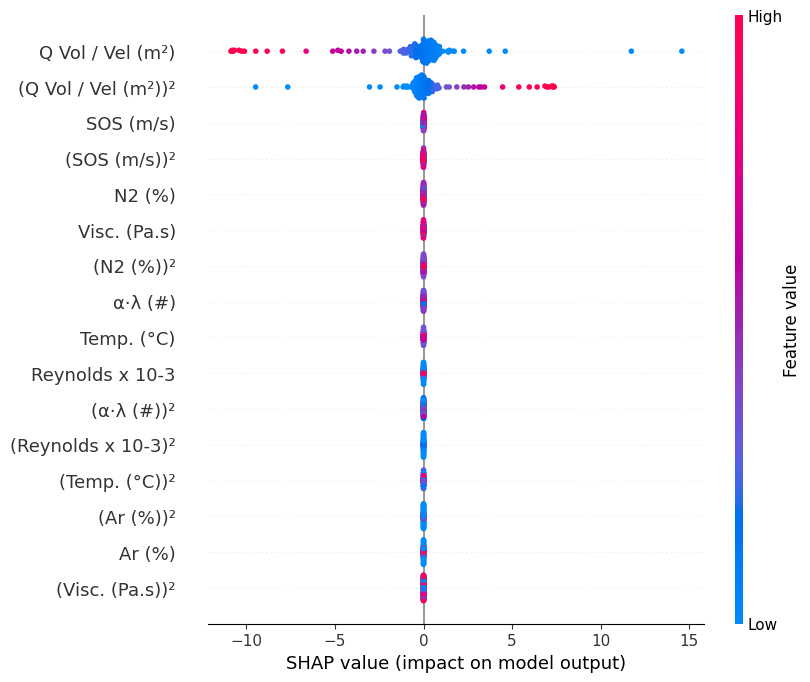

In [18]:
shap.plots.beeswarm(shap_values,max_display=50)

In [19]:
sklearn.metrics.mean_absolute_error()

TypeError: missing a required argument: 'y_true'

In [ ]:
ydata_col = 'Erro ([%])'

xdata,ydata = read_and_split_file(file,ydata_col)
xdata = strip_constant(xdata)

xtrain,xtest,ytrain,ytest = train_test_split(
    xdata,ydata,
    train_size=0.8,
    random_state=42
)
xtrain=xtrain.values

models = generate_models(xdata)
fit_models(models,xtrain,ytrain)

print(
    '''
    Model training complete
     
    Beginning nested cross-validation'''
)

best_models = extract_best_estimator(models)

n_repeats = 40
cvs_dict = cross_validate(best_models,xtrain,ytrain,generate_kfolds(n_repeats=n_repeats))

scores_dict = compute_scores(
    cvs_dict,
    xtrain,ytrain,
    generate_kfolds(n_repeats=n_repeats)
)

In [ ]:
yt = np.squeeze(ytrain.values)

nplots = len(cvs_dict)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))

for (name,cvs),ax_cal,ax_res in zip(cvs_dict.items(),axs[:,0],axs[:,1], ):
    
    coefs,covar,fit_err = compute_fit(yt,cvs,n_repeats)
    
    plot_vals(ax_cal,yt,cvs)
    plot_vals(ax_res,yt,cvs,resid=True)
    
    plot_fit(ax_cal,coefs,covar,fit_err)
    ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)

In [ ]:
Compare_reg.visualize(
    scores_dict,
    n_repeats=n_repeats,asymmetric=True
)    

In [ ]:
ignore = np.nan
if np.isnan(ignore):
    key = lambda k: np.median(
        np.asarray(scores_dict[k])[~np.isnan(scores_dict[k])]
    )
else:
    key = lambda k: np.median(
        np.asarray(scores_dict[k])[np.asarray(scores_dict[k]) != ignore]
    )

order = sorted(scores_dict, key=key, reverse=True)

fig,ax = plt.subplots()

h = ax.boxplot(
    [scores_dict[name] for name in order][::-1],
    #[scr for name,scr in scores_dict.items()],
    tick_labels=order[::-1],
    vert=False
)
#ax.invert_xaxis()
ax.set_xlim(-1,1)

#for name,scr in scores_dict.items():
#    ax.boxplot(scr)

In [ ]:
import xgboost